In [1]:
from continuous import *
from qutip import *
import numpy as np

%reload_ext autoreload
%autoreload 2

In [2]:
def apply_loss_dephasing(state, gamma_loss, gamma_dephasing, max_loss_level=10):
    kraus_list = NoiseChannels.get_loss_kraus_list(self.N, gamma_loss, max_level=max_loss_level)
    dephasing_super = NoiseChannels.get_dephasing_channel(self.N, gamma_dephasing)
    # dephasing_tensor = super_tensor(dephasing_super, dephasing_super)
    I = qeye(self.N)
    after_loss = sum([kraus_list[i] * state * kraus_list[i].dag() for i in range(max_loss_level)])
    return dephasing_super(after_loss)

In [3]:
N = 2

# initiate bell state
state = tensor(basis(N, 0) , basis(N, 0)) + tensor(basis(N, 1) , basis(N, 1))
state = state.unit()

helper = ContinuousProtocol(state, res = 10, m_i = 8, m_c = 8)

In [4]:
noisy_state = helper._add_noise(state, gamma_loss=0.01, gamma_dephasing=0.01, max_loss_level=10).unit()

In [5]:
fidelity(state, noisy_state)

0.9925344667596375

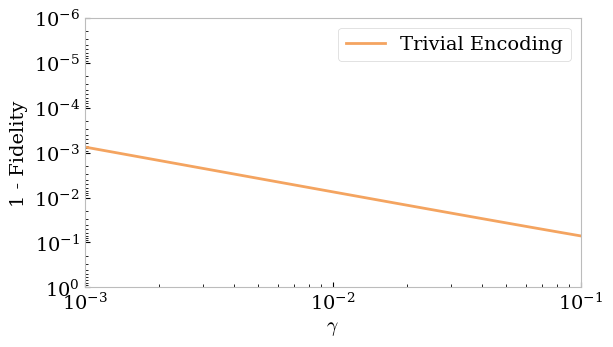

In [7]:
import matplotlib as mpl
import matplotlib.pyplot as plt

plt.style.use('bmh')
mpl.rcParams['font.family'] = 'DejaVu Serif'
mpl.rcParams["axes.facecolor"] = "w"
# ax = plt.axes()
# ax.set_facecolor("w")

mpl.rc('xtick', labelsize=14) 
mpl.rc('ytick', labelsize=14) 

plt.figure(dpi=100, figsize = (6.4,3.5))
plt.rcParams['font.size'] = 14


gamma = np.logspace(-3, -1, 100)

fidelity_list = np.array([
    fidelity(
        state, 
        helper._add_noise(state, gamma_loss=g, gamma_dephasing=g, max_loss_level=10).unit()
    ) for g in gamma
])

import matplotlib.pyplot as plt

plt.plot(gamma, 1-fidelity_list, 'sandybrown')
plt.xscale('log')
plt.yscale('log')
plt.gca().invert_yaxis()
plt.xlabel('$\\gamma$', fontsize=14)
plt.ylabel('1 - Fidelity', fontsize=14)
plt.grid()
plt.legend(['Trivial Encoding'], loc='upper right')

plt.ylim([1,1e-6])
plt.xlim([1e-3,1e-1])

plt.savefig('trivial_encoding_fidelity.svg', bbox_inches='tight')

In [10]:
# plot again with plotly
import plotly.graph_objects as go
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=gamma,
    y=1-fidelity_list,
    mode='lines+markers',
    name='Trivial Encoding',
    line=dict(color='sandybrown'),
    marker=dict(size=5)
))

fig.update_layout(
    xaxis=dict(type='log', title='$\\gamma$', title_font=dict(size=14)),
    yaxis=dict(type='log', title='1 - Fidelity', title_font=dict(size=14)),
    legend=dict(font=dict(size=12)),
    margin=dict(l=40, r=40, t=40, b=40)
)
fig.update_yaxes(autorange='reversed')

# fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'line': {'color': 'sandybrown'},
              'marker': {'size': 5},
              'mode': 'lines+markers',
              'name': 'Trivial Encoding',
              'type': 'scatter',
              'x': {'bdata': ('/Knx0k1iUD/9i2jZBCpRP2tIiFM++1' ... 'JvZVO3Pz6IYZC6b7g/mpmZmZmZuT8='),
                    'dtype': 'f8'},
              'y': {'bdata': ('AKC2V5KQSD8AALng3LtJPwAIqhFk9U' ... 'JPuL6wP6iVhi0AgbE/KDGrbYtLsj8='),
                    'dtype': 'f8'}}],
    'layout': {'legend': {'font': {'size': 12}},
               'margin': {'b': 40, 'l': 40, 'r': 40, 't': 40},
               'template': '...',
               'xaxis': {'title': {'font': {'size': 14}, 'text': '$\\gamma$'}, 'type': 'log'},
               'yaxis': {'autorange': 'reversed', 'title': {'font': {'size': 14}, 'text': '1 - Fidelity'}, 'type': 'log'}}
})